# **UTS Graph Data Science**

**Topik:** Python Driver Neo4j dan Sistem Rekomendasi

Abdullah Al-Firdaus Nuzula | 24031554008


# **1. Tugas Pendahuluan**


## **1.1 Persiapan Lingkungan**


### **Virtual Environment**

Saya menggunakan virtual environment `myenv` agar package UTS terpisah dari Python global. Environment dibuat dan diaktifkan melalui PowerShell:

```powershell
python -m venv myenv
.\myenv\Scripts\Activate.ps1
```


### **Requirements**

Daftar package mengikuti panduan UTS dan tersimpan di `requirements.txt`. Pilih kernel `myenv`, lalu jalankan sel instalasi berikut.


In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### **Dependency**

Dependency Neo4j dari panduan digunakan untuk koneksi dan query Cypher. `pandas` dan `numpy` membantu wrangling data; `scipy` menyimpan VSM sebagai sparse matrix; `networkx` dan `matplotlib` membuat serta menampilkan plot. Semua package tercantum di `requirements.txt` dan dipasang melalui cell instalasi pada bagian 1.1.


## **1.2 Penggunaan Driver Neo4j**


**Catatan implementasi:** Panduan UTS mencontohkan `driver.execute_query()` dan `RoutingControl`. Environment tugas ini menggunakan `neo4j==4.2.1` sesuai `requirements.txt`, sehingga query dijalankan melalui `driver.session(database="neo4j")` dan `session.run()`. Penyesuaian ini mengikuti API driver yang tersedia; query Cypher dan operasi graph tetap sama.


### **Koneksi ke Neo4j**


In [2]:
from getpass import getpass
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))
driver = GraphDatabase.driver(URI, auth=AUTH)

with driver.session(database="neo4j") as session:
    session.run("RETURN 1").consume()

print("Koneksi ke database neo4j berhasil.")

Koneksi ke database neo4j berhasil.


### **Membuat graph pertemanan**


In [3]:
friends_to_add = ["Guinevere", "Lancelot", "Merlin"]

with driver.session(database="neo4j") as session:
    for friend in friends_to_add:
        session.run(
            "MERGE (a:Person {name: $name}) "
            "MERGE (f:Person {name: $friend}) "
            "MERGE (a)-[:KNOWS]->(f)",
            name="Arthur",
            friend=friend,
        ).consume()

    result = session.run(
        "MATCH (:Person {name: $name})-[:KNOWS]->(f:Person) "
        "RETURN f.name AS name ORDER BY name",
        name="Arthur",
    )
    print("\n".join(record["name"] for record in result))

driver.close()

Guinevere
Lancelot
Merlin


Output:

```text
Guinevere
Lancelot
Merlin
```

Setiap relationship `KNOWS` mengarah dari Arthur ke salah satu temannya. Graph dapat dilihat di Neo4j Browser dengan query berikut:

```cypher
MATCH (a:Person)-[r:KNOWS]->(f:Person)
WHERE a.name = "Arthur"
RETURN a, r, f;
```


![Visualisasi Graph Pertemanan](images/checkpoint_neo4j_relationships.png)


**1. Apa nama database yang digunakan?**

Database yang digunakan adalah `neo4j`, sesuai pilihan pada `driver.session(database="neo4j")`.


**2. Bagaimana mengakses database lain dalam satu instance?**

Lihat daftar database dengan `SHOW DATABASES` pada database `system`. Untuk menjalankan query pada database lain, pilih database di session driver atau awali query Cypher dengan `USE nama_database`:

```cypher
USE nama_database
MATCH (n)
RETURN n;
```

Database tujuan harus sudah ada dan akun harus memiliki izin akses.


**3. Apa jenis graf pertemanan yang dibuat?**

Grafnya berarah. Pola `(a)-[:KNOWS]->(f)` membuat arah dari Arthur ke temannya; arah sebaliknya tidak dibuat.


## **1.3 Impor Data RetailRocket**


### **1. Mengunduh Dataset RetailRocket**

Dataset RetailRocket diperoleh dari Kaggle. Dari folder project, unduh dataset melalui Windows PowerShell:

```powershell
curl.exe -L -o ecommerce-dataset.zip `
  https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset
```

Ekstrak ZIP ke folder `data`, misalnya dengan perintah:

```powershell
Expand-Archive -LiteralPath .\ecommerce-dataset.zip -DestinationPath .\data
```

File yang digunakan notebook adalah `data/events.csv`.


### **2. Struktur Dataset**

File `events.csv` menjadi sumber data impor. File ini memiliki lima kolom:

| Kolom | Keterangan |
|---|---|
| `timestamp` | Waktu terjadinya event dalam format Unix epoch |
| `visitorid` | ID pengunjung |
| `event` | Jenis interaksi: `view`, `addtocart`, atau `transaction` |
| `itemid` | ID produk |
| `transactionid` | ID transaksi; kosong jika event bukan transaksi |

Data akan dimodelkan sebagai node `Visitor` dan `Item`. Jenis event menentukan relationship: `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`.


### **3. Membuat Driver dan Session Neo4j**

Driver dibuat dengan `GraphDatabase.driver(URI, auth=AUTH)`, lalu session dibuka untuk database `neo4j`. Database ini dipilih sebagai tujuan penyimpanan graph RetailRocket. Session memakai `session.run()` agar sesuai dengan Neo4j Python Driver 4.2.1. Context manager `with` menutup session dan driver setelah proses selesai.


### **4. Impor Data dengan Mekanisme Batch**

File dibaca bertahap dengan ukuran `BATCH_SIZE = 5_000`, sehingga seluruh CSV tidak perlu dimuat sekaligus ke memori. Setiap batch dikirim ke Neo4j, lalu jumlah event yang selesai diproses dihitung dan ditampilkan secara berkala. Sebelum impor, query membuat constraint unik untuk ID pengunjung dan produk.


### **5. Query Cypher untuk Impor Batch**

Query Cypher berada pada variabel `IMPORT_QUERY` dan dijalankan dengan `session.run(IMPORT_QUERY, batch=batch)`. `UNWIND $batch AS row` memproses setiap baris dalam batch. `MERGE` mencocokkan atau membuat node `Visitor` dan `Item` berdasarkan ID. Kondisi event menentukan relationship `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`; relationship menyimpan timestamp, dan `BOUGHT` juga menyimpan ID transaksi.

Relationship memakai `MERGE` dengan `eventId` yang berasal dari nomor baris CSV. Dengan begitu, jika cell dijalankan ulang, baris yang sama tidak membuat relationship duplikat. Bentuk ini menyesuaikan contoh PDF dengan implementasi `session.run()` yang kompatibel dengan driver 4.2.1.


In [5]:
import csv
from getpass import getpass
from pathlib import Path
from neo4j import GraphDatabase

CSV_PATH = Path("data/events.csv")
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))
BATCH_SIZE = 5_000
CONSTRAINTS = [
    """
    CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
    FOR (v:Visitor)
    REQUIRE v.visitorId IS UNIQUE
    """,
    """
    CREATE CONSTRAINT item_id_unique IF NOT EXISTS
    FOR (i:Item)
    REQUIRE i.itemId IS UNIQUE
    """,
]

if not CSV_PATH.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {CSV_PATH.resolve()}")

IMPORT_QUERY = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
    MERGE (v)-[r:VIEWED {eventId: row.eventId}]->(i)
    SET r.timestamp = row.timestamp
)
FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
    MERGE (v)-[r:ADDED_TO_CART {eventId: row.eventId}]->(i)
    SET r.timestamp = row.timestamp
)
FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
    MERGE (v)-[r:BOUGHT {eventId: row.eventId}]->(i)
    SET r.timestamp = row.timestamp,
        r.transactionId = row.transactionid
)
"""

def event_batches(path, batch_size):
    batch = []
    with path.open("r", encoding="utf-8-sig", newline="") as source:
        reader = csv.DictReader(source)
        for event_id, row in enumerate(reader, start=1):
            transaction_id = row["transactionid"].strip()
            batch.append({
                "eventId": event_id,
                "timestamp": int(row["timestamp"]),
                "visitorid": int(row["visitorid"]),
                "event": row["event"].strip(),
                "itemid": int(row["itemid"]),
                "transactionid": int(transaction_id) if transaction_id else None,
            })
            if len(batch) == batch_size:
                yield batch
                batch = []
        if batch:
            yield batch

processed = 0
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        for query in CONSTRAINTS:
            session.run(query).consume()

        for batch in event_batches(CSV_PATH, BATCH_SIZE):
            session.run(IMPORT_QUERY, batch=batch).consume()
            processed += len(batch)
            if processed % 100_000 == 0:
                print(f"Diproses: {processed:,} event")

print(f"Total event diproses: {processed:,}")

Diproses: 100,000 event
Diproses: 200,000 event
Diproses: 300,000 event
Diproses: 400,000 event
Diproses: 500,000 event
Diproses: 600,000 event
Diproses: 700,000 event
Diproses: 800,000 event
Diproses: 900,000 event
Diproses: 1,000,000 event
Diproses: 1,100,000 event
Diproses: 1,200,000 event
Diproses: 1,300,000 event
Diproses: 1,400,000 event
Diproses: 1,500,000 event
Diproses: 1,600,000 event
Diproses: 1,700,000 event
Diproses: 1,800,000 event
Diproses: 1,900,000 event
Diproses: 2,000,000 event
Diproses: 2,100,000 event
Diproses: 2,200,000 event
Diproses: 2,300,000 event
Diproses: 2,400,000 event
Diproses: 2,500,000 event
Diproses: 2,600,000 event
Diproses: 2,700,000 event
Total event diproses: 2,756,101


### **Hasil Impor dan Verifikasi**

Cell impor menyelesaikan **2.756.101 event**. Jumlah relationship pada Neo4j Browser cocok dengan jumlah baris dataset:

| Jenis relationship | Jumlah |
|---|---:|
| `VIEWED` | 2.664.312 |
| `ADDED_TO_CART` | 69.332 |
| `BOUGHT` | 22.457 |
| **Total RetailRocket** | **2.756.101** |

Query verifikasi yang digunakan di Neo4j Browser:

```cypher
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jenis_relasi;
```

Relasi `KNOWS` sebanyak 3 berasal dari latihan pertemanan pada bagian 1.2 dan tidak termasuk total data RetailRocket.


![Visualisasi Graph Pertemanan](images/checkpoint_neo4j_import.png)


# **2. Soal UTS**

## **2.1 Wrangling dan EDA**

### **2.1.1 Penentuan Periode Data**

P1 digunakan untuk training dan P2 untuk testing. Masing-masing berlangsung 9 hari. Batas akhir tidak termasuk dalam rentang, jadi data tepat pada 12 Mei 2015 pukul 00.00 WIB hanya masuk ke P2.

| Fold | Mulai (WIB) | Batas akhir (WIB, tidak termasuk) | Durasi | Unix timestamp (ms) |
|---|---|---|---:|---|
| P1 (training) | 3 Mei 2015, 00.00 | 12 Mei 2015, 00.00 | 9 hari | 1430586000000 - 1431363600000 |
| P2 (testing) | 12 Mei 2015, 00.00 | 21 Mei 2015, 00.00 | 9 hari | 1431363600000 - 1432141200000 |


### **2.1.2 Filter Timestamp dan Simpan CSV**

Filter `events.csv` memakai rentang P1 dan P2. Batas awal termasuk, batas akhir tidak. Hasil kedua periode disimpan ke `data/events_p1_p2.csv` dengan kolom asli tetap dipertahankan.


In [31]:
import csv
from pathlib import Path

SOURCE_PATH = Path("data/events.csv")
OUTPUT_PATH = Path("data/events_p1_p2.csv")
PERIODS = {
    "P1": (1430586000000, 1431363600000),
    "P2": (1431363600000, 1432141200000),
}

counts = {fold: 0 for fold in PERIODS}

if not SOURCE_PATH.is_file():
    raise FileNotFoundError(f"File sumber tidak ditemukan: {SOURCE_PATH.resolve()}")

with SOURCE_PATH.open("r", encoding="utf-8-sig", newline="") as source, OUTPUT_PATH.open(
    "w", encoding="utf-8", newline=""
) as target:
    reader = csv.DictReader(source)
    writer = csv.DictWriter(target, fieldnames=reader.fieldnames)
    writer.writeheader()

    for row in reader:
        timestamp = int(row["timestamp"])
        for fold, (start, end) in PERIODS.items():
            if start <= timestamp < end:
                writer.writerow(row)
                counts[fold] += 1
                break

print(f"File tersimpan: {OUTPUT_PATH}")
for fold, count in counts.items():
    print(f"{fold}: {count:,} event")
print(f"Total: {sum(counts.values()):,} event")


File tersimpan: data\events_p1_p2.csv
P1: 156,465 event
P2: 206,207 event
Total: 362,672 event


P1 berisi 156.465 event dan P2 berisi 206.207 event. Totalnya 362.672 event.

### **2.1.3 Komposisi Subgraph**

Query menghitung simpul `Visitor` dan `Item` yang memiliki event pada P1 atau P2. Batas waktunya sama dengan filter CSV.


In [32]:
from getpass import getpass
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))

COMPOSITION_QUERY = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE (r.timestamp >= $p1_start AND r.timestamp < $p1_end)
   OR (r.timestamp >= $p2_start AND r.timestamp < $p2_end)
RETURN count(DISTINCT v) AS jumlah_visitor,
       count(DISTINCT i) AS jumlah_item
"""

PERIOD_PARAMS = {
    "p1_start": 1430586000000,
    "p1_end": 1431363600000,
    "p2_start": 1431363600000,
    "p2_end": 1432141200000,
}

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        record = session.run(COMPOSITION_QUERY, **PERIOD_PARAMS).single()

print(f"Visitor: {record['jumlah_visitor']:,} simpul")
print(f"Item: {record['jumlah_item']:,} simpul")

Visitor: 189,719 simpul
Item: 88,025 simpul


Subgraph P1 dan P2 memiliki **189.719 simpul Visitor** dan **88.025 simpul Item**. Python mengambil hasil hitung dari query Cypher menggunakan `session.run()`. `MATCH` memilih simpul dan event. `WHERE` membatasi event berdasarkan `timestamp`. `count(DISTINCT ...)` menghitung setiap simpul satu kali. Python menjalankan query dengan `session.run()` dan mengambil satu record hasil.


### **2.1.4 Vector Space Modelling (VSM) User-Item**

Pada VSM User, setiap `Visitor` menjadi satu baris dan setiap `Item` menjadi satu dimensi. Nilainya adalah jumlah event pasangan User–Item. Matriks disimpan dalam format sparse karena sebagian besar pasangan tidak memiliki interaksi.


Package analisis pada bagian ini sudah tercantum di `requirements.txt` dan dipasang melalui cell instalasi pada bagian 1.1.


In [33]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from pathlib import Path

VSM_CSV_PATH = Path("data/events_p1_p2.csv")
events = pd.read_csv(VSM_CSV_PATH)

user_ids = np.sort(events["visitorid"].unique())
item_ids = np.sort(events["itemid"].unique())
user_index = {user_id: index for index, user_id in enumerate(user_ids)}
item_index = {item_id: index for index, item_id in enumerate(item_ids)}

row_indices = events["visitorid"].map(user_index).to_numpy()
column_indices = events["itemid"].map(item_index).to_numpy()
event_values = np.ones(len(events), dtype=np.int32)

user_item_vsm = csr_matrix(
    (event_values, (row_indices, column_indices)),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.int32,
)
user_item_vsm.sum_duplicates()

total_cells = user_item_vsm.shape[0] * user_item_vsm.shape[1]
density = user_item_vsm.nnz / total_cells
sparsity = 1 - density

print("Jumlah User:", f"{user_item_vsm.shape[0]:,}")
print("Jumlah dimensi Item:", f"{user_item_vsm.shape[1]:,}")
print("Shape matriks:", user_item_vsm.shape)
print("Pasangan User-Item dengan interaksi:", f"{user_item_vsm.nnz:,}")
print("Kepadatan matriks:", f"{density:.8%}")
print("Sparsity matriks:", f"{sparsity:.6%}")

Jumlah User: 189,719
Jumlah dimensi Item: 88,025
Shape matriks: (189719, 88025)
Pasangan User-Item dengan interaksi: 282,541
Kepadatan matriks: 0.00169186%
Sparsity matriks: 99.998308%


**Karakteristik VSM:** Shape matriks adalah **(189.719, 88.025)**: 189.719 User dan 88.025 dimensi Item. Dari 16.700.014.975 kemungkinan pasangan, 282.541 berisi interaksi. Kepadatan matriks sekitar **0,001692%** dan sparsity-nya **99,998308%**. Format CSR menyimpan nilai yang ada saja.


#### **Plot Subgraph dengan NetworkX**

Plot memakai 5 User dengan event terbanyak dan hingga 3 Item teratas per User. Sisi menunjukkan interaksi, sedangkan bobotnya menunjukkan jumlah event.


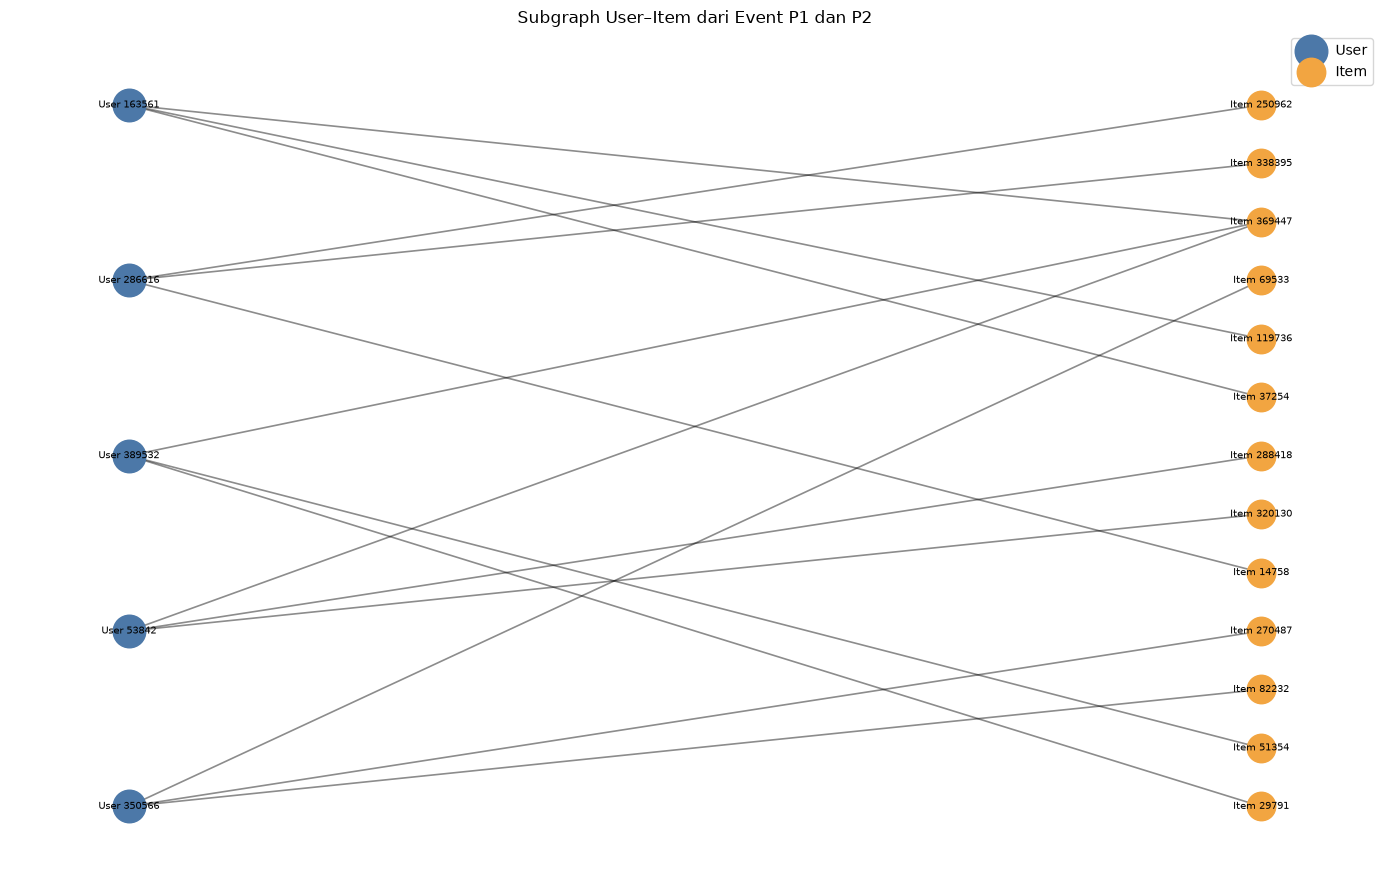

In [34]:
import networkx as nx
import matplotlib.pyplot as plt

top_users = events.groupby("visitorid").size().nlargest(5).index
user_item_counts = (
    events[events["visitorid"].isin(top_users)]
    .groupby(["visitorid", "itemid"])
    .size()
    .reset_index(name="jumlah_event")
    .sort_values(["visitorid", "jumlah_event"], ascending=[True, False])
    .groupby("visitorid", sort=False)
    .head(3)
)

G_vsm = nx.Graph()
for row in user_item_counts.itertuples(index=False):
    user_node = f"User {row.visitorid}"
    item_node = f"Item {row.itemid}"
    G_vsm.add_edge(user_node, item_node, weight=int(row.jumlah_event))

user_nodes = [node for node in G_vsm if node.startswith("User ")]
item_nodes = [node for node in G_vsm if node.startswith("Item ")]
positions = nx.bipartite_layout(G_vsm, user_nodes, align="vertical")

plt.figure(figsize=(14, 9))
nx.draw_networkx_edges(G_vsm, positions, alpha=0.45, width=1.2)
nx.draw_networkx_nodes(G_vsm, positions, nodelist=user_nodes, node_color="#4C78A8", node_size=550, label="User")
nx.draw_networkx_nodes(G_vsm, positions, nodelist=item_nodes, node_color="#F2A541", node_size=420, label="Item")
nx.draw_networkx_labels(G_vsm, positions, font_size=7)
plt.title("Subgraph User–Item dari Event P1 dan P2")
plt.legend(scatterpoints=1)
plt.axis("off")
plt.tight_layout()
plt.show()


#### **Plot Subgraph dengan Neo4J**

![Visualisasi Graph Pertemanan](images/checkpoint_neo4j_user_item.png)

### **2.1.5 Vector Space Modelling (VSM) Item-User**

Pada VSM Item, setiap `Item` menjadi satu baris dan setiap `Visitor` menjadi satu dimensi. Nilainya adalah jumlah event pasangan Item–User. Matriks disimpan dalam format sparse.


In [35]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from pathlib import Path

VSM_CSV_PATH = Path("data/events_p1_p2.csv")
events_item = pd.read_csv(VSM_CSV_PATH)

item_ids = np.sort(events_item["itemid"].unique())
user_ids = np.sort(events_item["visitorid"].unique())
item_index = {item_id: index for index, item_id in enumerate(item_ids)}
user_index = {user_id: index for index, user_id in enumerate(user_ids)}

row_indices = events_item["itemid"].map(item_index).to_numpy()
column_indices = events_item["visitorid"].map(user_index).to_numpy()
event_values = np.ones(len(events_item), dtype=np.int32)

item_user_vsm = csr_matrix(
    (event_values, (row_indices, column_indices)),
    shape=(len(item_ids), len(user_ids)),
    dtype=np.int32,
)
item_user_vsm.sum_duplicates()

total_cells_item = item_user_vsm.shape[0] * item_user_vsm.shape[1]
density_item = item_user_vsm.nnz / total_cells_item
sparsity_item = 1 - density_item

print("Jumlah Item:", f"{item_user_vsm.shape[0]:,}")
print("Jumlah dimensi User:", f"{item_user_vsm.shape[1]:,}")
print("Shape matriks:", item_user_vsm.shape)
print("Pasangan Item-User dengan interaksi:", f"{item_user_vsm.nnz:,}")
print("Kepadatan matriks:", f"{density_item:.8%}")
print("Sparsity matriks:", f"{sparsity_item:.6%}")

Jumlah Item: 88,025
Jumlah dimensi User: 189,719
Shape matriks: (88025, 189719)
Pasangan Item-User dengan interaksi: 282,541
Kepadatan matriks: 0.00169186%
Sparsity matriks: 99.998308%


**Karakteristik VSM:** Shape matriks adalah **(88.025, 189.719)**: 88.025 Item dan 189.719 dimensi User. Dari 16.700.014.975 kemungkinan pasangan, 282.541 berisi interaksi. Kepadatan matriks sekitar **0,001692%** dan sparsity-nya **99,998308%**. Jumlah nilai tak nol sama dengan VSM User; hanya baris dan kolomnya yang bertukar.

#### **Plot Subgraph dengan NetworkX**

Plot menampilkan 5 Item dengan event terbanyak dan hingga 3 User teratas per Item. Node biru menunjukkan Item, node jingga menunjukkan User, dan sisi menunjukkan interaksi.


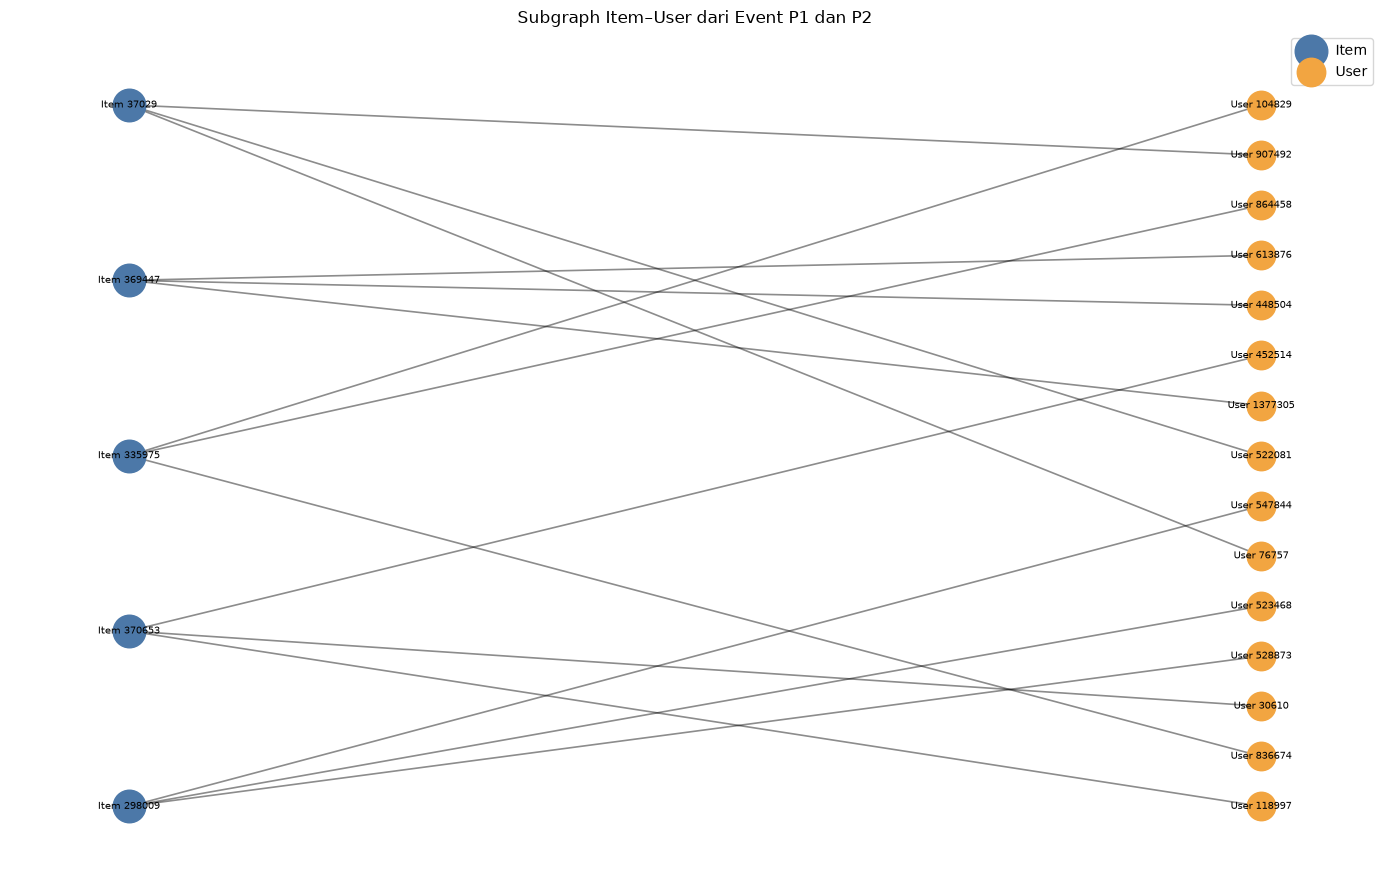

In [36]:
import networkx as nx
import matplotlib.pyplot as plt

top_items = events_item.groupby("itemid").size().nlargest(5).index
item_user_counts = (
    events_item[events_item["itemid"].isin(top_items)]
    .groupby(["itemid", "visitorid"])
    .size()
    .reset_index(name="jumlah_event")
    .sort_values(["itemid", "jumlah_event"], ascending=[True, False])
    .groupby("itemid", sort=False)
    .head(3)
)

G_item_vsm = nx.Graph()
for row in item_user_counts.itertuples(index=False):
    item_node = f"Item {row.itemid}"
    user_node = f"User {row.visitorid}"
    G_item_vsm.add_edge(item_node, user_node, weight=int(row.jumlah_event))

item_nodes_plot = [node for node in G_item_vsm if node.startswith("Item ")]
user_nodes_plot = [node for node in G_item_vsm if node.startswith("User ")]
positions_item = nx.bipartite_layout(G_item_vsm, item_nodes_plot, align="vertical")

plt.figure(figsize=(14, 9))
nx.draw_networkx_edges(G_item_vsm, positions_item, alpha=0.45, width=1.2)
nx.draw_networkx_nodes(G_item_vsm, positions_item, nodelist=item_nodes_plot, node_color="#4C78A8", node_size=550, label="Item")
nx.draw_networkx_nodes(G_item_vsm, positions_item, nodelist=user_nodes_plot, node_color="#F2A541", node_size=420, label="User")
nx.draw_networkx_labels(G_item_vsm, positions_item, font_size=7)
plt.title("Subgraph Item–User dari Event P1 dan P2")
plt.legend(scatterpoints=1)
plt.axis("off")
plt.tight_layout()
plt.show()


#### **Plot Subgraph dengan Neo4J**

![Visualisasi Graph Pertemanan](images/checkpoint_neo4j_item_user.png)

### **2.1.6 Perbandingan VSM User dan Item**

Kedua matriks berisi pasangan interaksi yang sama, tetapi orientasinya berbeda. VSM User berukuran **(189.719, 88.025)**, sedangkan VSM Item **(88.025, 189.719)**. Keduanya memiliki 282.541 nilai tak nol dan tingkat sparsity yang sama.

Matriks ini memiliki 88.025 vektor, dibandingkan 189.719 vektor pada VSM User. Pengurangannya dihitung terhadap jumlah vektor User: `(189.719 - 88.025) / 189.719 × 100% = 53,6%`. Jadi, VSM Item memiliki 53,6% lebih sedikit vektor sebagai kandidat perbandingan.

Jumlah vektor yang lebih sedikit belum membuktikan waktu komputasi lebih cepat. Setiap vektor Item memiliki lebih banyak dimensi, sementara jumlah nilai tak nol dan sparsity kedua matriks sama. Karena itu, kebutuhan memori diperkirakan sebanding dan kecepatan perlu diuji langsung. VSM User lebih sesuai untuk mencari User dengan pola interaksi serupa.

Karena tujuan tugas ini adalah merekomendasikan Item, saya memilih VSM Item untuk membandingkan pola interaksi antar-Item secara langsung; jumlah vektornya yang lebih sedikit menjadi keuntungan tambahan.


### **2.1.7 Perhitungan Similarity pada Proyeksi Item**

Cosine similarity membandingkan Item berdasarkan pola User yang berinteraksi dengannya. Item dengan jumlah event terbanyak dipilih sebagai acuan. Kode membandingkannya dengan Item lain, lalu menampilkan 10 nilai similarity tertinggi. Kode tidak membentuk matriks similarity untuk semua pasangan Item.

In [37]:
import numpy as np
import pandas as pd

if "item_user_vsm" not in globals():
    raise RuntimeError("Jalankan cell pembentukan VSM Item pada bagian 2.1.5 terlebih dahulu.")

item_event_counts = np.asarray(item_user_vsm.sum(axis=1)).ravel()
target_index = int(item_event_counts.argmax())
target_item_id = item_ids[target_index]

item_norms = np.sqrt(item_user_vsm.multiply(item_user_vsm).sum(axis=1)).A1
target_vector = item_user_vsm.getrow(target_index)
dot_products = (item_user_vsm @ target_vector.T).toarray().ravel()
denominators = item_norms * item_norms[target_index]
similarities = np.divide(
    dot_products,
    denominators,
    out=np.zeros_like(dot_products, dtype=float),
    where=denominators > 0,
)
similarities[target_index] = 0.0

top_indices = np.argsort(similarities)[::-1][:10]
similarity_table = pd.DataFrame({
    "itemid": item_ids[top_indices],
    "cosine_similarity": similarities[top_indices],
})

print("Item acuan:", int(target_item_id))
print("Jumlah event pada Item acuan:", f"{item_event_counts[target_index]:,.0f}")
print("\n10 Item paling mirip:")
print(similarity_table.to_string(index=False, formatters={"cosine_similarity": "{:.4f}".format}))

Item acuan: 369447
Jumlah event pada Item acuan: 1,013

10 Item paling mirip:
 itemid cosine_similarity
 274435            0.5264
 356129            0.5049
 224582            0.4560
 219687            0.4319
 379935            0.3774
  43557            0.3200
 257597            0.2952
 272327            0.2473
 442024            0.2280
 341223            0.2280


Item acuan adalah Item dengan event terbanyak. Item lain diurutkan berdasarkan kemiripannya dengan Item acuan. Perhitungan memakai frekuensi interaksi dan tidak memperhitungkan waktu terjadinya event.

#### **2.1.7(a) Query Cypher untuk Mendapatkan Lima Similarity Tertinggi**

Query mengurutkan relationship `SIMILAR_TO` yang tersimpan dan mengambil lima nilai tertinggi. Parameter `$source_item_id` menerima ID Item acuan dari hasil Python. Di Neo4j Browser, tetapkan parameter dengan `:param {source_item_id: 369447}` sebelum menjalankan query.

```cypher
MATCH (source:Item {itemId: $source_item_id})-[r:SIMILAR_TO]->(similar:Item)
RETURN source.itemId AS item_acuan,
       similar.itemId AS item_serupa,
       r.cosineSimilarity AS similarity
ORDER BY similarity DESC
LIMIT 5
```
#### **2.1.7(b) Menuliskan Nilai Similarity ke Graf**

Query menyimpan seluruh 10 baris dari `similarity_table` sebagai relationship berarah `SIMILAR_TO`. Query (a) kemudian memilih lima nilai tertinggi. `MERGE` memakai relationship yang sama saat cell dijalankan ulang, lalu `SET` menyimpan nilainya.

```cypher
UNWIND $similarities AS row
MATCH (source:Item {itemId: row.source_item_id})
MATCH (similar:Item {itemId: row.similar_item_id})
MERGE (source)-[r:SIMILAR_TO]->(similar)
SET r.cosineSimilarity = row.cosine_similarity
```


In [38]:
from getpass import getpass
from neo4j import GraphDatabase

if "similarity_table" not in globals() or "target_item_id" not in globals():
    raise RuntimeError("Jalankan cell similarity pada bagian 2.1.7 terlebih dahulu.")

similarity_rows = [
    {
        "source_item_id": int(target_item_id),
        "similar_item_id": int(row.itemid),
        "cosine_similarity": float(row.cosine_similarity),
    }
    for row in similarity_table.itertuples(index=False)
]

WRITE_SIMILARITY_QUERY = """
UNWIND $similarities AS row
MATCH (source:Item {itemId: row.source_item_id})
MATCH (similar:Item {itemId: row.similar_item_id})
MERGE (source)-[r:SIMILAR_TO]->(similar)
SET r.cosineSimilarity = row.cosine_similarity
"""

TOP5_SIMILARITY_QUERY = """
MATCH (source:Item {itemId: $source_item_id})-[r:SIMILAR_TO]->(similar:Item)
RETURN source.itemId AS item_acuan,
       similar.itemId AS item_serupa,
       r.cosineSimilarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        session.run(WRITE_SIMILARITY_QUERY, similarities=similarity_rows).consume()
        records = session.run(
            TOP5_SIMILARITY_QUERY,
            source_item_id=int(target_item_id),
        ).data()

print("Item acuan:", int(target_item_id))
print("Lima similarity tertinggi dari graph:")
for record in records:
    print(
        f"Item {record['item_acuan']} -> Item {record['item_serupa']}: "
        f"{record['similarity']:.4f}"
    )

Item acuan: 369447
Lima similarity tertinggi dari graph:
Item 369447 -> Item 274435: 0.5264
Item 369447 -> Item 356129: 0.5049
Item 369447 -> Item 224582: 0.4560
Item 369447 -> Item 219687: 0.4319
Item 369447 -> Item 379935: 0.3774


![Visualisasi Graph Pertemanan](images/checkpoint_neo4j_centrality.png)

`UNWIND` membaca hasil Python sebagai baris. `MATCH` mencari kedua simpul Item, `MERGE` membuat atau memakai relationship, lalu `SET` menyimpan cosine similarity. Query (a) mengurutkan nilai dan menampilkan lima hasil teratas. Cell dapat dijalankan ulang karena `MERGE` memakai relationship yang sama.

### **2.1.8 Graph Sebelum dan Sesudah Similarity**

Gunakan Item `369447` sebagai acuan, sesuai hasil bagian 2.1.7. Jalankan query pertama di Neo4j Browser dan pilih tampilan **Graph** untuk melihat hingga 25 event antara Visitor dan Item tersebut pada P1/P2.

```cypher
MATCH (visitor:Visitor)-[event]->(item:Item {itemId: 369447})
WHERE (event.timestamp >= 1430586000000 AND event.timestamp < 1431363600000)
   OR (event.timestamp >= 1431363600000 AND event.timestamp < 1432141200000)
RETURN visitor, event, item
LIMIT 25
```

![Graph sebelum similarity](images/checkpoint_neo4j_before_centrality.png)

Setelah similarity disimpan, jalankan query berikut. Tampilan **Graph** menunjukkan Item acuan, lima Item serupa, dan nilai `cosineSimilarity` pada setiap relationship.

```cypher
MATCH (source:Item {itemId: 369447})-[similarity:SIMILAR_TO]->(neighbor:Item)
RETURN source, similarity, neighbor
ORDER BY similarity.cosineSimilarity DESC
LIMIT 5
```

![Graph sesudah similarity](images/checkpoint_neo4j_after_centrality.png)


## **2.2 Analytics**


### **2.2.1 User-based KNN dan Rekomendasi Item**

User dipilih secara acak dengan seed `42`, sehingga hasilnya dapat diulang. Calon User harus memiliki interaksi P1 dan item relevan P2 yang juga ada di katalog P1. Skrip memilih calon pertama yang memiliki lima tetangga positif dan minimal lima kandidat rekomendasi.

P1 menjadi data training dan P2 data uji. Interaksi P1 diubah menjadi nilai biner. Cosine similarity memilih lima tetangga; skor item adalah jumlah similarity tetangga yang pernah berinteraksi dengannya. Item yang sudah dilihat User target dikeluarkan.


In [39]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from pathlib import Path

RANDOM_SEED = 42
K_NEIGHBORS = 5
TOP_N = 5
P1_START, P1_END = 1430586000000, 1431363600000
P2_START, P2_END = 1431363600000, 1432141200000

analytics_events = pd.read_csv(Path("data/events_p1_p2.csv"))
train_events = analytics_events[
    (analytics_events["timestamp"] >= P1_START)
    & (analytics_events["timestamp"] < P1_END)
].copy()
test_events = analytics_events[
    (analytics_events["timestamp"] >= P2_START)
    & (analytics_events["timestamp"] < P2_END)
].copy()

user_ids = np.sort(train_events["visitorid"].unique())
item_ids = np.sort(train_events["itemid"].unique())
user_index = {int(user_id): index for index, user_id in enumerate(user_ids)}
item_index = {int(item_id): index for index, item_id in enumerate(item_ids)}

train_rows = train_events["visitorid"].map(user_index).to_numpy()
train_columns = train_events["itemid"].map(item_index).to_numpy()
user_item_train = csr_matrix(
    (np.ones(len(train_events), dtype=np.float32), (train_rows, train_columns)),
    shape=(len(user_ids), len(item_ids)),
)
user_item_train.sum_duplicates()
user_item_train.data[:] = 1
user_norms = np.sqrt(np.asarray(user_item_train.multiply(user_item_train).sum(axis=1)).ravel())

test_known = test_events[test_events["itemid"].isin(item_index)]
candidate_users = np.intersect1d(user_ids, test_known["visitorid"].unique())
rng = np.random.default_rng(RANDOM_SEED)
selected_user_id = None

for candidate_user in rng.permutation(candidate_users):
    candidate_user = int(candidate_user)
    target_row = user_index[candidate_user]
    target_vector = user_item_train.getrow(target_row)
    dot_products = (user_item_train @ target_vector.T).toarray().ravel()
    denominators = user_norms * user_norms[target_row]
    user_similarities = np.divide(
        dot_products, denominators,
        out=np.zeros_like(dot_products, dtype=float),
        where=denominators > 0,
    )
    user_similarities[target_row] = 0.0
    neighbor_indices = np.flatnonzero(user_similarities > 0)
    if len(neighbor_indices) < K_NEIGHBORS:
        continue

    neighbor_order = np.lexsort((user_ids[neighbor_indices], -user_similarities[neighbor_indices]))
    knn_indices = neighbor_indices[neighbor_order[:K_NEIGHBORS]]
    knn_similarities = user_similarities[knn_indices]
    item_scores = np.asarray(user_item_train[knn_indices].T.dot(knn_similarities)).ravel()
    item_scores[target_vector.indices] = 0.0  # Jangan rekomendasikan item yang sudah ada di P1
    recommendation_candidates = np.flatnonzero(item_scores > 0)
    if len(recommendation_candidates) < TOP_N:
        continue

    recommendation_order = np.lexsort((item_ids[recommendation_candidates], -item_scores[recommendation_candidates]))
    top_indices = recommendation_candidates[recommendation_order[:TOP_N]]
    selected_user_id = candidate_user
    selected_knn_ids = user_ids[knn_indices]
    selected_knn_similarities = knn_similarities
    recommended_item_ids = item_ids[top_indices]
    recommended_scores = item_scores[top_indices]
    break

if selected_user_id is None:
    raise RuntimeError("Tidak ditemukan User yang memenuhi syarat KNN dan rekomendasi.")

relevant_item_ids = set(
    test_known.loc[test_known["visitorid"] == selected_user_id, "itemid"].astype(int)
)
print(f"Seed acak: {RANDOM_SEED}")
print(f"User terpilih: {selected_user_id}")
print(f"Jumlah kandidat User yang dapat dievaluasi: {len(candidate_users):,}")
print("\n5 tetangga terdekat:")
for neighbor_id, similarity in zip(selected_knn_ids, selected_knn_similarities):
    print(f"Visitor {int(neighbor_id)} | cosine similarity = {similarity:.4f}")
print("\n3 item rekomendasi:")
for item_id, score in zip(recommended_item_ids[:3], recommended_scores[:3]):
    print(f"Item {int(item_id)} | skor = {score:.4f}")
print("\nDaftar top-5 untuk evaluasi:", [int(item_id) for item_id in recommended_item_ids])

Seed acak: 42
User terpilih: 835647
Jumlah kandidat User yang dapat dievaluasi: 3,830

5 tetangga terdekat:
Visitor 786637 | cosine similarity = 0.4472
Visitor 1228586 | cosine similarity = 0.4472
Visitor 598380 | cosine similarity = 0.2582
Visitor 772062 | cosine similarity = 0.2582
Visitor 695657 | cosine similarity = 0.1414

3 item rekomendasi:
Item 409365 | skor = 0.5164
Item 359309 | skor = 0.2582
Item 450830 | skor = 0.2582

Daftar top-5 untuk evaluasi: [409365, 359309, 450830, 58765, 66974]


**Hasil:** User terpilih adalah **835647**. Lima tetangganya: Visitor **786637** (0,4472), **1228586** (0,4472), **598380** (0,2582), **772062** (0,2582), dan **695657** (0,1414).

Tiga rekomendasi teratas adalah Item **409365**, **359309**, dan **450830**. Daftar top-5 untuk evaluasi: **409365, 359309, 450830, 58765, 66974**.


### **2.2.2 Evaluasi Hit@5 dan NDCG@5**

Item relevan diambil dari interaksi User pada P2 yang juga ada di katalog P1. `Hit@5` bernilai 1 jika top-5 memuat setidaknya satu item relevan. `NDCG@5` memberi nilai lebih tinggi jika item relevan berada di posisi atas.


In [40]:
top5_recommendations = [int(item_id) for item_id in recommended_item_ids[:5]]
relevance_at_5 = [int(item_id in relevant_item_ids) for item_id in top5_recommendations]

hit_at_5 = int(any(relevance_at_5))
dcg_at_5 = sum(
    relevance / np.log2(rank + 1)
    for rank, relevance in enumerate(relevance_at_5, start=1)
)
ideal_hits = min(len(relevant_item_ids), 5)
idcg_at_5 = sum(1 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1))
ndcg_at_5 = dcg_at_5 / idcg_at_5 if idcg_at_5 else 0.0

print("Item relevan pada P2:", sorted(relevant_item_ids))
print("Relevansi pada posisi top-5:", relevance_at_5)
print(f"Hit@5: {hit_at_5}")
print(f"NDCG@5: {ndcg_at_5:.4f}")

Item relevan pada P2: [19629, 65426, 159873, 181973, 216678, 364327, 461279]
Relevansi pada posisi top-5: [0, 0, 0, 0, 0]
Hit@5: 0
NDCG@5: 0.0000


**Hasil evaluasi User 835647:** Dari lima item rekomendasi teratas, tidak terdapat item yang muncul pada himpunan item relevan User 835647 di periode P2. Oleh karena itu, `Hit@5 = 0`. Karena tidak terdapat item relevan pada seluruh posisi top-5, nilai `DCG@5 = 0`, sehingga `NDCG@5 = 0,0000`. Hasil ini menunjukkan bahwa untuk User 835647, metode User-based KNN yang digunakan belum berhasil merekomendasikan item yang kemudian berinteraksi dengan user pada periode testing P2. Evaluasi ini hanya berlaku untuk user terpilih sesuai instruksi soal dan bukan merupakan performa rata-rata sistem rekomendasi.
